<a href="https://colab.research.google.com/github/tuannguyen2209/Fundamentals-of-Data-Science-and-AI-UEH/blob/main/chapter_2_python_code.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [49]:
!pip install pandas scikit-learn numpy matplotlib seaborn

In [66]:
from google.colab import drive
import pandas as pd
import numpy as np
from sklearn.impute import SimpleImputer
from sklearn.compose import ColumnTransformer
from IPython.display import display
from sklearn.preprocessing import MinMaxScaler, StandardScaler
import matplotlib.pyplot as plt
import seaborn as sns
import sqlite3

In [7]:
drive.mount('/content/drive')
file_path = '/content/drive/MyDrive/NMTTFundamentals of Data Science and AI/Horse_Colic_Orange_v2.xlsx'
dtype_codes = {
    'Hospital Number': str,
    'lesion_type_1': str,
    'lesion_type_2': str,
    'type of lesion 3': str
}

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [8]:
df = pd.read_excel(file_path, sheet_name='Orange_Data', skiprows=[1, 2], dtype=dtype_codes)
print(f"Size of dataset: {df.shape[0]} rows, {df.shape[1]} columns\n")

Kích thước dữ liệu sạch: 368 dòng, 29 cột



# **Basic Descriptive Statistics**

---



In [18]:

num_cols = df.select_dtypes(include=[np.number]).columns.tolist()
cat_cols = [c for c in df.select_dtypes(exclude=[np.number]).columns if c != 'Hospital Number']

desc_num = df[num_cols].describe().T
desc_num['median'] = df[num_cols].median()
desc_num['missing'] = df[num_cols].isnull().sum()
desc_num['missing_%'] = (df[num_cols].isnull().mean() * 100).round(2)
desc_num['skewness'] = df[num_cols].skew().round(2)
desc_num = desc_num[['count', 'missing', 'missing_%', 'mean', 'std', 'min', '25%', 'median', '75%', 'max', 'skewness']].round(2)
desc_cat = df[cat_cols].describe().T
desc_cat['missing'] = df[cat_cols].isnull().sum()
desc_cat['missing_%'] = (df[cat_cols].isnull().mean() * 100).round(2)
desc_cat['top_%'] = ((desc_cat['freq'] / desc_cat['count']) * 100).astype(float).round(2)
desc_cat = desc_cat[['count', 'missing', 'missing_%', 'unique', 'top', 'freq', 'top_%']]
print("Description Statistic")
display(desc_cat)
print("")
display(desc_num)

Description Statistic


,count,missing,missing_%,unique,top,freq,top_%
dataset_split,368,0,0.00,2,train,300,81.52
surgery,366,2,0.54,2,yes_surgery,214,58.47
temperature_extremities,303,65,17.66,4,cool,135,44.55
peripheral_pulse,285,83,22.55,4,normal,151,52.98
mucous_membranes,320,48,13.04,6,normal_pink,98,30.63
capillary_refill_time,330,38,10.33,3,under_3_seconds,232,70.30
pain,305,63,17.12,5,intermittent_mild_pain,82,26.89
peristalsis,316,52,14.13,4,hypomotile,154,48.73
abdominal_distension,303,65,17.66,4,none,101,33.33
nasogastric_tube,237,131,35.60,3,slight,121,51.05


,count,missing,missing_%,mean,std,min,25%,median,75%,max,skewness
Age,368.0,0,0.00,1.61,2.12,1.0,1.00,1.0,1.0,9.0,3.21
rectal temperature,299.0,69,18.75,38.13,0.71,35.4,37.80,38.1,38.5,40.8,0.02
pulse,342.0,26,7.07,70.76,28.09,30.0,48.00,60.0,88.0,184.0,1.07
respiratory_rate,297.0,71,19.29,30.52,17.67,8.0,18.00,28.0,36.0,96.0,1.58
nasogastric_reflux_ph,69.0,299,81.25,4.96,2.00,1.0,3.50,5.4,6.5,8.5,-0.46
packed_cell_volume,331.0,37,10.05,45.96,10.52,23.0,37.75,44.0,52.0,75.0,0.73
total_protein,325.0,43,11.68,6.81,1.07,3.3,6.10,6.7,7.5,13.0,0.67
abdominocentesis_total_protein,133.0,235,63.86,2.95,1.93,0.1,2.00,2.1,3.9,10.1,1.39


#**Removing Rows with Missing Values**


##Method 1:
Remove rows with mising data

In [28]:
def method_1(data):
    df_clean = df.dropna().copy()

    print(f"Original rows: {len(df)}")
    print(f"Remaining rows: {len(df_clean)}")

    display(df_clean)

method_1(df)

Original rows: 368
Remaining rows: 7


,dataset_split,surgery,Age,Hospital Number,rectal temperature,pulse,respiratory_rate,temperature_extremities,peripheral_pulse,mucous_membranes,...,packed_cell_volume,total_protein,abdominocentesis_appearance,abdominocentesis_total_protein,outcome,surgical_lesion,lesion_type_1,lesion_type_2,type of lesion 3,cp_data
10,train,yes_surgery,1,528548,38.1,66.0,12.0,cool,reduced,bright_red_injected,...,44.0,6.0,cloudy,3.6,lived,yes,02124,00000,00000,yes
54,train,no_surgery,1,529461,40.3,114.0,36.0,cool,reduced,normal_pink,...,57.0,8.1,serosanguinous,4.5,euthanized,yes,07400,00000,00000,yes
64,train,yes_surgery,1,529667,39.0,64.0,36.0,cool,normal,pale_cyanotic,...,44.0,7.5,serosanguinous,5.0,lived,yes,02113,00000,00000,yes
91,train,no_surgery,1,529461,40.3,114.0,36.0,cool,reduced,normal_pink,...,57.0,8.1,serosanguinous,4.5,died,yes,03205,00000,00000,yes
104,train,yes_surgery,1,527563,37.8,52.0,24.0,normal,reduced,pale_pink,...,48.0,6.6,clear,3.7,died,yes,05400,00000,00000,no
189,train,yes_surgery,1,5299603,38.3,60.0,16.0,cool,normal,normal_pink,...,30.0,6.0,clear,3.0,lived,yes,31110,00000,00000,no
313,test,yes_surgery,1,528999,37.9,120.0,60.0,cool,reduced,pale_pink,...,52.0,6.6,serosanguinous,1.8,died,yes,03205,00000,00000,yes


##Method 2:
Remove rows with mising data

In [39]:
def method_2(data, strategy="mean"):
    X = data.copy()

    numeric_vars = X.select_dtypes(exclude=['object']).columns.to_list()

    imputer = SimpleImputer(strategy=strategy)
    ct = ColumnTransformer(
        [("imputer", imputer, numeric_vars)],
        remainder="drop"
    ).set_output(transform="pandas")

    X_transform = ct.fit_transform(X)

    print(f"Missing obs:({strategy}): {len(X_transform)}")
    print(f"Remaining (NaN): {X_transform.isnull().sum().sum()}")
    display(X_transform.head())
    return X_transform


##Method 3:
Imputing Missing Values

In [36]:
def method_3(data):
    X = data.copy()
    numeric_vars = X.select_dtypes(exclude=['object']).columns.to_list()
    imputer = SimpleImputer(strategy="mean", add_indicator=True)

    ct = ColumnTransformer(
        [("imputer", imputer, numeric_vars)],
        remainder="drop"
    ).set_output(transform="pandas")

    ct.fit(X)
    X_transform = ct.transform(X)

    print(f"Size of table before Method 3: {X_transform.shape[0]} Rows, {X_transform.shape[1]} Columns")
    print(f"Remaning missing obs (NaN): {X_transform.isnull().sum().sum()}")
    display(df_m3.head())
    return X_transform



##Printing the result after removing missing values

In [40]:
if __name__ == '__main__':
  df = pd.read_excel(file_path, sheet_name='Orange_Data', skiprows=[1, 2], dtype=dtype_codes)
  method_1(df)
  df_imputed_num = method_2(df, strategy="median")
  df_m3 = method_3(df)

Original rows: 368
Remaining rows: 7


,dataset_split,surgery,Age,Hospital Number,rectal temperature,pulse,respiratory_rate,temperature_extremities,peripheral_pulse,mucous_membranes,...,packed_cell_volume,total_protein,abdominocentesis_appearance,abdominocentesis_total_protein,outcome,surgical_lesion,lesion_type_1,lesion_type_2,type of lesion 3,cp_data
10,train,yes_surgery,1,528548,38.1,66.0,12.0,cool,reduced,bright_red_injected,...,44.0,6.0,cloudy,3.6,lived,yes,02124,00000,00000,yes
54,train,no_surgery,1,529461,40.3,114.0,36.0,cool,reduced,normal_pink,...,57.0,8.1,serosanguinous,4.5,euthanized,yes,07400,00000,00000,yes
64,train,yes_surgery,1,529667,39.0,64.0,36.0,cool,normal,pale_cyanotic,...,44.0,7.5,serosanguinous,5.0,lived,yes,02113,00000,00000,yes
91,train,no_surgery,1,529461,40.3,114.0,36.0,cool,reduced,normal_pink,...,57.0,8.1,serosanguinous,4.5,died,yes,03205,00000,00000,yes
104,train,yes_surgery,1,527563,37.8,52.0,24.0,normal,reduced,pale_pink,...,48.0,6.6,clear,3.7,died,yes,05400,00000,00000,no
189,train,yes_surgery,1,5299603,38.3,60.0,16.0,cool,normal,normal_pink,...,30.0,6.0,clear,3.0,lived,yes,31110,00000,00000,no
313,test,yes_surgery,1,528999,37.9,120.0,60.0,cool,reduced,pale_pink,...,52.0,6.6,serosanguinous,1.8,died,yes,03205,00000,00000,yes


Missing obs:(median): 368
Remaining (NaN): 0


,imputer__Age,imputer__rectal temperature,imputer__pulse,imputer__respiratory_rate,imputer__nasogastric_reflux_ph,imputer__packed_cell_volume,imputer__total_protein,imputer__abdominocentesis_total_protein
0,1.0,38.5,66.0,28.0,5.4,45.0,8.4,2.1
1,1.0,39.2,88.0,20.0,5.4,50.0,8.5,2.0
2,1.0,38.3,40.0,24.0,5.4,33.0,6.7,2.1
3,9.0,39.1,164.0,84.0,5.0,48.0,7.2,5.3
4,1.0,37.3,104.0,35.0,5.4,74.0,7.4,2.1


Size of table before Method 3: 368 Rows, 15 Columns
Remaning missing obs (NaN): 0


,imputer__Age,imputer__rectal temperature,imputer__pulse,imputer__respiratory_rate,imputer__nasogastric_reflux_ph,imputer__packed_cell_volume,imputer__total_protein,imputer__abdominocentesis_total_protein,imputer__missingindicator_rectal temperature,imputer__missingindicator_pulse,imputer__missingindicator_respiratory_rate,imputer__missingindicator_nasogastric_reflux_ph,imputer__missingindicator_packed_cell_volume,imputer__missingindicator_total_protein,imputer__missingindicator_abdominocentesis_total_protein
0,1.0,38.5,66.0,28.0,4.962319,45.0,8.4,2.94812,0.0,0.0,0.0,1.0,0.0,0.0,1.0
1,1.0,39.2,88.0,20.0,4.962319,50.0,8.5,2.00000,0.0,0.0,0.0,1.0,0.0,0.0,0.0
2,1.0,38.3,40.0,24.0,4.962319,33.0,6.7,2.94812,0.0,0.0,0.0,1.0,0.0,0.0,1.0
3,9.0,39.1,164.0,84.0,5.000000,48.0,7.2,5.30000,0.0,0.0,0.0,0.0,0.0,0.0,0.0
4,1.0,37.3,104.0,35.0,4.962319,74.0,7.4,2.94812,0.0,0.0,0.0,1.0,0.0,0.0,1.0


# **Handling Duplicate Data**


In [41]:
def duplicated_check_and_remove(data):
    X = data.copy()
    print(f"Original Rows: {len(X)}")
    exact_dups = X.duplicated().sum()
    print(f"Duplicate rows: {exact_dups}")
    hosp_dups = X.duplicated(subset=['Hospital Number']).sum()
    print(f"Duplicate 'Hospital Number'  rows : {hosp_dups}")
    if hosp_dups > 0:
        display(X[X.duplicated(subset=['Hospital Number'], keep=False)][['dataset_split', 'Hospital Number', 'surgery', 'outcome', 'pulse']].sort_values('Hospital Number').head(6))

    X.drop_duplicates(subset=['Hospital Number'], keep='first', inplace=True)
    print(f"\n Remaining Rows:'): {len(X)}")
    return X

df_no_dup = duplicated_check_and_remove(df)

Số dòng ban đầu: 368
Số dòng trùng lặp hoàn toàn (tất cả cột): 0
Số dòng có mã 'Hospital Number' bị lặp: 22

Ví dụ các ca bệnh có cùng Hospital Number:


,dataset_split,Hospital Number,surgery,outcome,pulse
362,test,5274919,yes_surgery,died,78.0
351,test,5274919,yes_surgery,died,78.0
282,train,527544,yes_surgery,died,70.0
110,train,527544,yes_surgery,died,70.0
166,train,527916,yes_surgery,lived,40.0
160,train,527916,yes_surgery,lived,NaN



Số dòng còn lại sau khi chạy drop_duplicates(subset=['Hospital Number'], keep='first'): 346


# **Data Normalization sample**

In [46]:
features = [
    'rectal temperature',
    'pulse',
    'respiratory_rate',
    'nasogastric_reflux_ph',
    'packed_cell_volume',
    'total_protein',
    'abdominocentesis_total_protein'
]
def normalising(X, y):
    scaler = MinMaxScaler()
    X_normalized = X.copy()
    X_normalized[features] = scaler.fit_transform(X[features])
    print("=== Normalized Data (MinMaxScaler [0, 1]) ===")
    display(X_normalized[features].head())
    return X_normalized

def standardizing(X, y):
    scaler_z = StandardScaler()
    X_standardized = X.copy()
    X_standardized[features] = scaler_z.fit_transform(X[features])
    print("\n=== Standardized Data (StandardScaler Z-score) ===")
    display(X_standardized[features].head())
    return X_standardized

# Tách X và y tương tự code mẫu
X = df.drop(columns=['surgical_lesion', 'dataset_split', 'Hospital Number'])
y = df['surgical_lesion']

# Chạy 2 hàm biến đổi
X_norm = normalising(X, y)
X_std = standardizing(X, y)

=== Normalized Data (MinMaxScaler [0, 1]) ===


,rectal temperature,pulse,respiratory_rate,nasogastric_reflux_ph,packed_cell_volume,total_protein,abdominocentesis_total_protein
0,0.574074,0.233766,0.227273,NaN,0.423077,0.525773,NaN
1,0.703704,0.376623,0.136364,NaN,0.519231,0.536082,0.19
2,0.537037,0.064935,0.181818,NaN,0.192308,0.350515,NaN
3,0.685185,0.870130,0.863636,0.533333,0.480769,0.402062,0.52
4,0.351852,0.480519,0.306818,NaN,0.980769,0.422680,NaN



=== Standardized Data (StandardScaler Z-score) ===


,rectal temperature,pulse,respiratory_rate,nasogastric_reflux_ph,packed_cell_volume,total_protein,abdominocentesis_total_protein
0,0.514505,-0.169609,-0.142965,NaN,-0.091137,1.488397,NaN
1,1.499736,0.614740,-0.596483,NaN,0.384674,1.581889,-0.493863
2,0.233010,-1.096565,-0.369724,NaN,-1.233085,-0.100972,NaN
3,1.358989,3.324306,3.031660,0.018942,0.194350,0.366490,1.225061
4,-1.174464,1.185175,0.253863,NaN,2.668569,0.553474,NaN


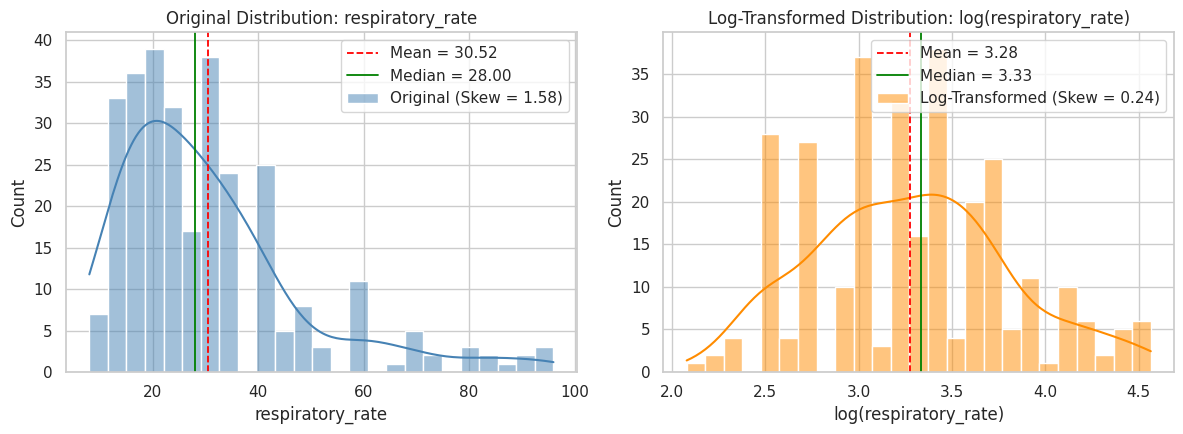

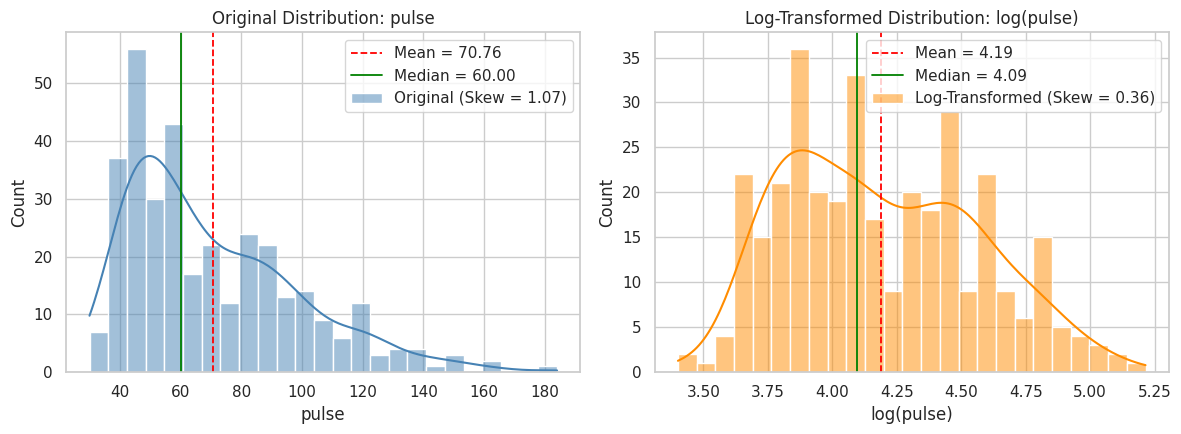

In [52]:
sns.set_theme(style="whitegrid")

def log_transformation_sns(df, column='respiratory_rate'):
    fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 4.5))
    data = df[column].dropna()
    log_data = np.log(data)
    sns.histplot(data, bins=25, kde=True, color='steelblue', ax=ax1, label=f"Original (Skew = {data.skew():.2f})")
    ax1.axvline(data.mean(), color='red', linestyle='--', linewidth=1.3, label=f"Mean = {data.mean():.2f}")
    ax1.axvline(data.median(), color='green', linestyle='-', linewidth=1.3, label=f"Median = {data.median():.2f}")
    ax1.set_title(f"Original Distribution: {column}")
    ax1.set_xlabel(column)
    ax1.legend()

    sns.histplot(log_data, bins=25, kde=True, color='darkorange', ax=ax2, label=f"Log-Transformed (Skew = {log_data.skew():.2f})")
    ax2.axvline(log_data.mean(), color='red', linestyle='--', linewidth=1.3, label=f"Mean = {log_data.mean():.2f}")
    ax2.axvline(log_data.median(), color='green', linestyle='-', linewidth=1.3, label=f"Median = {log_data.median():.2f}")
    ax2.set_title(f"Log-Transformed Distribution: log({column})")
    ax2.set_xlabel(f"log({column})")
    ax2.legend()

    plt.tight_layout()
    plt.show()
    return log_data
log_resp = log_transformation_sns(df, column='respiratory_rate')
log_pulse = log_transformation_sns(df, column='pulse')

In [54]:
num_cols = [
    'rectal temperature',
    'pulse',
    'respiratory_rate',
    'nasogastric_reflux_ph',
    'packed_cell_volume',
    'total_protein',
    'abdominocentesis_total_protein'
]
X_clean = df[num_cols].fillna(df[num_cols].median())

def vector_normalization(df_input, mode="column"):
    X = df_input.copy()

    if mode == "row":
        #Row-wise Normalization
        row_norms = np.linalg.norm(X.values, axis=1)
        normalized_df = X.div(row_norms, axis=0)
    else:
        # Column-wise Normalization
        col_norms = np.linalg.norm(X.values, axis=0)
        normalized_df = X.div(col_norms, axis=1)

    return normalized_df
df_col_norm = vector_normalization(X_clean, mode="column")
df_row_norm = vector_normalization(X_clean, mode="row")

print("Column-wise L2 Normalization")
display(df_col_norm.head(3))

print(" Row-wise L2 Normalization")
display(df_row_norm.head(3))

Column-wise L2 Normalization


,rectal temperature,pulse,respiratory_rate,nasogastric_reflux_ph,packed_cell_volume,total_protein,abdominocentesis_total_protein
0,0.052630,0.045819,0.042962,0.052226,0.050084,0.063744,0.040546
1,0.053587,0.061092,0.030687,0.052226,0.055649,0.064502,0.038615
2,0.052356,0.027769,0.036825,0.052226,0.036728,0.050843,0.040546


 Row-wise L2 Normalization


,rectal temperature,pulse,respiratory_rate,nasogastric_reflux_ph,packed_cell_volume,total_protein,abdominocentesis_total_protein
0,0.411550,0.705514,0.299309,0.057724,0.481032,0.089793,0.022448
1,0.353655,0.793920,0.180436,0.048718,0.451091,0.076685,0.018044
2,0.552218,0.576729,0.346037,0.077858,0.475801,0.096602,0.030278


#**Data Grouping Sample**

In [65]:
#Outcome group
outcome_group = df.groupby("outcome")
print("Outcome Group")
display(outcome_group.describe())
#Grouping mutliple Columns
grouping = df.groupby(["outcome", "surgery"])
print("\nGrouping Multiple Columns")
display(grouping.describe())
#Aggregation with GroupBy
aggregated_group = df.groupby(['outcome',"surgery"]).agg(
    mean = ('Age',"mean"),
    meadian = ('Age',"median"),
    max = ('Age',"max"),
    min = ('Age',"min"),
    mean_temp = ('rectal temperature',"mean"),
    max_temp = ('rectal temperature',"max"),
    min_temp = ('rectal temperature',"min"),
    avarage_pulse = ('pulse',"mean"),
    count=("Hospital Number",'count'),
)
print("\nAggregation with GroupBy")
display(aggregated_group)


Outcome Group


Age                                               \
            count      mean       std  min  25%  50%  75%  max   
outcome                                                          
died         89.0  2.258427  2.929195  1.0  1.0  1.0  1.0  9.0   
euthanized   52.0  1.153846  1.109400  1.0  1.0  1.0  1.0  9.0   
lived       225.0  1.462222  1.870744  1.0  1.0  1.0  1.0  9.0   

           rectal temperature             ... total_protein        \
                        count       mean  ...           75%   max   
outcome                                   ...                       
died                     62.0  38.172581  ...           7.5   9.0   
euthanized               41.0  37.990244  ...           7.5  13.0   
lived                   194.0  38.154124  ...           7.3  11.0   

           abdominocentesis_total_protein                                     \
                                    count      mean       std  min  25%  50%   
outcome                                                                        
died                                 29.0  3.986207  2.055606  1.4  2.8  3.4   
euthanized                           30.0  2.323333  1.322923  1.0  2.0  2.0   
lived                                73.0  2.819178  1.947766  0.1  1.1  2.0   

                       
            75%   max  
outcome                
died        4.5  10.1  
euthanized  2.0   7.4  
lived       4.1   8.0  

[3 rows x 64 columns]


Grouping Multiple Columns


Age                                               \
                        count      mean       std  min  25%  50%  75%  max   
outcome    surgery                                                           
died       no_surgery    23.0  1.695652  2.304833  1.0  1.0  1.0  1.0  9.0   
           yes_surgery   66.0  2.454545  3.109201  1.0  1.0  1.0  1.0  9.0   
euthanized no_surgery    19.0  1.000000  0.000000  1.0  1.0  1.0  1.0  1.0   
           yes_surgery   33.0  1.242424  1.392621  1.0  1.0  1.0  1.0  9.0   
lived      no_surgery   110.0  1.436364  1.825041  1.0  1.0  1.0  1.0  9.0   
           yes_surgery  115.0  1.486957  1.921098  1.0  1.0  1.0  1.0  9.0   

                       rectal temperature             ... total_protein        \
                                    count       mean  ...           75%   max   
outcome    surgery                                    ...                       
died       no_surgery                17.0  38.182353  ...         7.325   8.5   
           yes_surgery               45.0  38.168889  ...         7.525   9.0   
euthanized no_surgery                15.0  37.900000  ...         7.725   8.4   
           yes_surgery               26.0  38.042308  ...         7.500  13.0   
lived      no_surgery                99.0  38.169697  ...         7.200   9.1   
           yes_surgery               95.0  38.137895  ...         7.500  11.0   

                       abdominocentesis_total_protein                      \
                                                count      mean       std   
outcome    surgery                                                          
died       no_surgery                             5.0  4.080000  1.380942   
           yes_surgery                           24.0  3.966667  2.193204   
euthanized no_surgery                             9.0  3.522222  1.905110   
           yes_surgery                           21.0  1.809524  0.402374   
lived      no_surgery                            31.0  2.496774  2.015520   
           yes_surgery                           42.0  3.057143  1.885004   

                                                  
                        min  25%  50%  75%   max  
outcome    surgery                                
died       no_surgery   2.2  3.6  4.1  4.5   6.0  
           yes_surgery  1.4  2.8  3.3  4.4  10.1  
euthanized no_surgery   1.0  2.3  3.3  4.5   7.4  
           yes_surgery  1.0  2.0  2.0  2.0   2.0  
lived      no_surgery   0.1  1.0  2.0  2.7   8.0  
           yes_surgery  0.9  2.0  2.0  4.3   8.0  

[6 rows x 64 columns]


Aggregation with GroupBy


mean  meadian  max  min  mean_temp  max_temp  \
outcome    surgery                                                         
died       no_surgery   1.695652      1.0    9    1  38.182353      40.3   
           yes_surgery  2.454545      1.0    9    1  38.168889      40.8   
euthanized no_surgery   1.000000      1.0    1    1  37.900000      40.3   
           yes_surgery  1.242424      1.0    9    1  38.042308      39.7   
lived      no_surgery   1.436364      1.0    9    1  38.169697      39.6   
           yes_surgery  1.486957      1.0    9    1  38.137895      39.9   

                        min_temp  avarage_pulse  count  
outcome    surgery                                      
died       no_surgery       36.0      87.904762     23  
           yes_surgery      36.4      89.160714     66  
euthanized no_surgery       36.0      84.111111     19  
           yes_surgery      35.4      77.000000     33  
lived      no_surgery       36.9      56.485714    110  
           yes_surgery      36.5      67.859813    115

#**Data export**

In [68]:
output_dir = '/content/drive/MyDrive/NMTTFundamentals of Data Science and AI/'
csv_path = output_dir + 'horse_colic_cleaned.csv'
df.to_csv(csv_path, index=False, encoding='utf-8-sig')
print(f"export CSV: {csv_path}")

excel_path = output_dir + 'horse_colic_cleaned.xlsx'
df.to_excel(excel_path, sheet_name='Cleaned_Data', index=False)
print(f" Exporting Excel: {excel_path}")

text_data = df.head(5).to_string(index=False)
print(text_data)
db_path = output_dir + 'horse_colic.db'
conn = sqlite3.connect(db_path)
df.to_sql('horse_colic_table', conn, if_exists='replace', index=False)
check_sql = pd.read_sql('SELECT COUNT(*) AS total_rows FROM horse_colic_table', conn)
conn.close()
print(f"\n Saved SQLite database ")

export CSV: /content/drive/MyDrive/NMTTFundamentals of Data Science and AI/horse_colic_cleaned.csv
 Exporting Excel: /content/drive/MyDrive/NMTTFundamentals of Data Science and AI/horse_colic_cleaned.xlsx
dataset_split     surgery  Age Hospital Number  rectal temperature  pulse  respiratory_rate temperature_extremities peripheral_pulse mucous_membranes capillary_refill_time                   pain peristalsis abdominal_distension nasogastric_tube nasogastric_reflux  nasogastric_reflux_ph rectal_examination_feces                   abdomen  packed_cell_volume  total_protein abdominocentesis_appearance  abdominocentesis_total_protein    outcome surgical_lesion lesion_type_1 lesion_type_2 type of lesion 3 cp_data
        train  no_surgery    1          530101                38.5   66.0              28.0                    cool          reduced              NaN     3_seconds_or_more continuous_severe_pain      absent               severe              NaN                NaN                   

#**Pivot table**

In [71]:
pivot_table = df.pivot_table(
    index="outcome",
    columns='surgery',
    values=['rectal temperature', 'pulse', 'respiratory_rate'],
    aggfunc=['mean', 'median', 'max', 'min'],
    margins = True,
    margins_name = 'Total',
    sort=True
).round(2)
display(pivot_table)

mean                                                    \
                pulse                    rectal temperature               
surgery    no_surgery yes_surgery  Total         no_surgery yes_surgery   
outcome                                                                   
died            87.90       89.16  88.60              38.18       38.17   
euthanized      84.11       77.00  77.54              37.90       38.04   
lived           56.49       67.86  60.56              38.17       38.14   
Total           61.58       74.89  68.97              38.11       38.11   

                                                          median  ...  \
                  respiratory_rate                         pulse  ...   
surgery     Total       no_surgery yes_surgery  Total no_surgery  ...   
outcome                                                           ...   
died        38.13            30.56       35.47  35.13       88.0  ...   
euthanized  37.94            23.73       33.97  28.20       85.0  ...   
lived       38.14            26.61       31.89  28.98       50.0  ...   
Total       38.11            26.03       33.55  30.20       52.0  ...   

                        max        min                                       \
           respiratory_rate      pulse                   rectal temperature   
surgery               Total no_surgery yes_surgery Total         no_surgery   
outcome                                                                       
died                   96.0       42.0        30.0  30.0               36.0   
euthanized             80.0       40.0        34.0  34.0               36.0   
lived                  96.0       36.0        30.0  30.0               36.9   
Total                  96.0       36.0        30.0  30.0               36.0   

                                                                 
                             respiratory_rate                    
surgery    yes_surgery Total       no_surgery yes_surgery Total  
outcome                                                          
died              36.4  36.0             12.0        12.0  12.0  
euthanized        35.4  35.4             12.0        12.0  12.0  
lived             36.5  36.5              9.0         8.0   8.0  
Total             35.4  35.4              9.0         8.0   8.0  

[4 rows x 36 columns]

#**Outlier Handling with a box Plot**

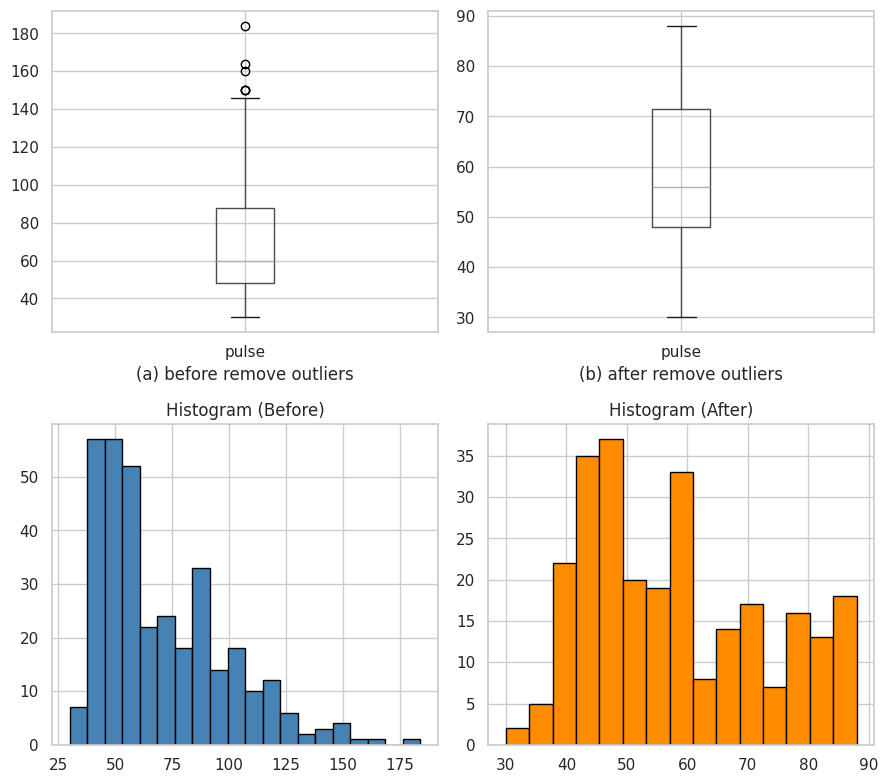

In [73]:
def  quantile_ds(df, columns):
  low = 0.25
  high = 0.75
  quant_df = df[columns].quantile([low,high])
  df_ret = df.copy()
  for col in columns:
    def_ret = df_ret[df_ret[col] >= quant_df.loc[low, col]]
    df_ret = df_ret[df_ret[col] <= quant_df.loc[high, col]]
  return df_ret
def draw_boxplot_all(ds, columns=['pulse']):
    df_bro = pd.DataFrame()
    for col in columns:
        df_bro[col] = pd.Series(ds[col].dropna().to_numpy())
    ds_clean = quantile_ds(ds, columns)

    df_aro = pd.DataFrame()
    for col in columns:
        df_aro[col] = pd.Series(ds_clean[col].dropna().to_numpy())
    fig, ((ax1, ax2), (ax3, ax4)) = plt.subplots(2, 2, figsize=(9, 8))

    df_bro.boxplot(ax=ax1, rot=0)
    df_bro.hist(ax=ax3, bins=20, color='steelblue', edgecolor='black')

    df_aro.boxplot(ax=ax2, rot=0)
    df_aro.hist(ax=ax4, bins=15, color='darkorange', edgecolor='black')

    ax1.set_xlabel('(a) before remove outliers')
    ax2.set_xlabel('(b) after remove outliers')
    ax3.set_title('Histogram (Before)')
    ax4.set_title('Histogram (After)')

    plt.tight_layout()
    plt.show()
draw_boxplot_all(df, columns=['pulse'])


#**Outlier Review with Z-score**

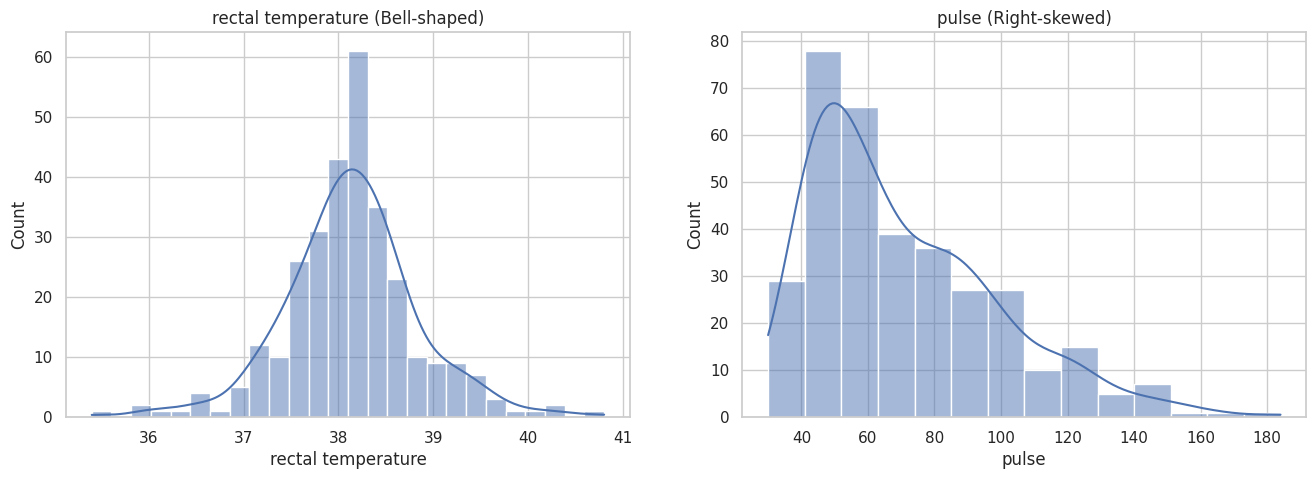

skew of pulse: 1.068257487776401
skew of rectal temperature: 0.01863604528354353

 Z-score of rectal temperature: [36.00, 40.27]
Outliers: 4


,Hospital Number,rectal temperature,outcome,surgical_lesion
44,535407,35.4,euthanized,yes
54,529461,40.3,euthanized,yes
91,529461,40.3,died,yes
259,527734,40.8,died,yes


Remained rows: 295


In [75]:
plt.figure(figsize=(16, 5))

plt.subplot(1, 2, 1)
sns.histplot(df['rectal temperature'], kde=True)
plt.title('rectal temperature (Bell-shaped)')

plt.subplot(1, 2, 2)
sns.histplot(df['pulse'], kde=True)
plt.title('pulse (Right-skewed)')

plt.show()

print(f"skew of pulse: {df['pulse'].skew()}")
print(f"skew of rectal temperature: {df['rectal temperature'].skew()}")

mean_temp = df['rectal temperature'].mean()
std_temp = df['rectal temperature'].std()

upper_limit = mean_temp + 3 * std_temp
lower_limit = mean_temp - 3 * std_temp

print(f"\n Z-score of rectal temperature: [{lower_limit:.2f}, {upper_limit:.2f}]")

outliers = df[(df['rectal temperature'] > upper_limit) | (df['rectal temperature'] < lower_limit)]
print(f"Outliers: {len(outliers)}")
display(outliers[['Hospital Number', 'rectal temperature', 'outcome', 'surgical_lesion']])
df_no_outliers_z = df[(df['rectal temperature'] >= lower_limit) & (df['rectal temperature'] <= upper_limit)]
print(f"Remained rows: {len(df_no_outliers_z)}")